# `panorama.spec` — Demo

Worked examples of the **`spec`** module of PANORAMA: reading and writing of 1D spectra, removal of spectral regions, continuum normalization and comparison with the diagnostic lines of OB stars.

The notebook uses three spectra of OB stars, read from `data_and_results/spec/data/`:

* `01179148_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf.fits` — HERMES (Mercator) merged spectrum, not normalized, stored as a FITS image on a ln λ scale.
* `HD886_20160709_050356_M_V85000.fits` — normalized spectrum of HD 886 from the IACOB spectroscopic database, stored as a FITS image.
* `HD36822_20111109_015842_M_V85000_RV.ascii` — normalized spectrum of HD 36822 (IACOB) in a two-column ASCII file.

The three spectra are distributed with the repository for demonstration purposes (see the *Demo* section of `READMEs/spec_README.md`).

* **Example 1** — reading the three spectra with `readspec` (FITS image on a ln λ scale, FITS image and ASCII file), with their wavelength coverage, sampling and median flux.
* **Example 2** — removal of bad points from the IACOB ASCII spectrum with `rmvspec` around He I 4471, Mg II 4481, He II 4542 and the Si III 4553-4575 triplet.
* **Example 3** — continuum normalization of the HERMES spectrum between 4000 and 5000 Å with `normspec`, with a set of recommended parameters (each one printed with the reason for its value) and the header lines that describe the fit in the output file.
* **Example 4** — comparison of the normalized HERMES spectrum, the IACOB FITS spectrum and the cleaned IACOB ASCII spectrum with `plotspec`, with the diagnostic lines of OB stars drawn and labeled (shown inline); the returned figure is saved with `savefig_pkl`.
* **Example 5** — writing spectra with `writespec`: the normalized HERMES spectrum as a gzip-compressed FITS table with a header, the IACOB FITS image converted to ASCII, a round trip with `readspec`, and the particular cases of `writespec` (descending wavelengths, non-finite fluxes, existing files, unsupported extensions, repeated wavelengths) with a *mock* 5-point spectrum.

`rmvspec` and `normspec` write their output spectra with `writespec`, so every file written by the notebook can be read back with `readspec`.

**Interactive mode:** with `INTERACTIVE = False` (default, first code cell) figures are shown inline: `rmvspec` returns the spectrum unmodified (with a warning) and `normspec` runs in batch mode and writes the automatic fit. Set `INTERACTIVE = True` to open the interactive windows of examples 2-4 in separate Qt windows (`%matplotlib qt`; needs PyQt6, installed with the `demos` extra, and a display): `rmvspec` and `normspec` wait until their window is closed (`w` saves the fit in `normspec`). Restart the kernel after changing the flag.

**Files:** outputs (cleaned, normalized and converted spectra, and the comparison figure) are written to `data_and_results/spec/results/` (relative to `Demos/`, the folder of this notebook). No internet access is needed. Run the cells in order (*Run All*).

## Imports

Python packages and PANORAMA functions (inline figures, or Qt windows if INTERACTIVE).

In [1]:
INTERACTIVE = False  # True: open the interactive windows of examples 2-4 in Qt windows (restart the kernel after changing it)

get_ipython().run_line_magic("matplotlib", "qt" if INTERACTIVE else "inline")  # Equivalent to '%matplotlib qt' / '%matplotlib inline'

from astropy.io import fits
import numpy as np
from pathlib import Path
import warnings

from panorama import (
                      normspec,  # SPECTRA
                      plotspec,  # SPECTRA
                      readspec,  # SPECTRA
                      rmvspec,  # SPECTRA
                      savefig_pkl,  # MATPLOTLIB (tex module)
                      writespec,  # SPECTRA
                     )

	PANORAMA v1.2.0 loaded...
		- To see the available functions, run:
			panorama.functions()          # Lists all functions, grouped by submodule
			panorama.functions('obs')     # Lists the functions of a single submodule
		- To see the docstring of a specific function (e.g. 'visibility'), run:
			help(panorama.visibility)
		- To silence this message, set the environment variable PANORAMA_QUIET=1



## Setup

Working directories, input and output spectra, wavelength windows and normalization parameters.

In [2]:
work_dir_data    = Path("./data_and_results/spec/data/")
work_dir_results = Path("./data_and_results/spec/results/")
work_dir_results.mkdir(parents=True, exist_ok=True)

hermes_file      = work_dir_data / "01179148_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf.fits"  # HERMES, not normalized, ln(lambda)
iacob_fits_file  = work_dir_data / "HD886_20160709_050356_M_V85000.fits"  # IACOB, normalized, FITS image
iacob_ascii_file = work_dir_data / "HD36822_20111109_015842_M_V85000_RV.ascii"  # IACOB, normalized, ASCII

clean_file           = work_dir_results / "HD36822_clean.txt"
norm_file            = work_dir_results / "HERMES_norm_4000-5000.txt"
norm_fits_file       = work_dir_results / "HERMES_norm_4000-5000.fits.gz"  # Example 5: gzip-compressed FITS table
iacob_converted_file = work_dir_results / "HD886_converted.txt"  # Example 5: FITS image -> ASCII
mock_file            = work_dir_results / "mock_spectrum.txt"  # Example 5: particular cases
compare_fig_file     = work_dir_results / "comparison_demo"  # Example 4: figure of 'plotspec' (PDF + pickle)

# Region compared in examples 2 and 4: He I 4471, Mg II 4481, Si III 4553-4575 and He II 4542
zoom_range = (4440., 4600.)  # Å

# Recommended normalization parameters for the HERMES spectrum of an OB star in 4000-5000 Å
# (value, reason) pairs: printed in example 3 and passed to 'normspec'
NORM_PARAMS = {
               'wave_lim'    : ((4000., 5000.), "Region normalized (Å): Hδ, Hγ, Hβ and the He I / He II / Si III lines"),
               'function'    : ("spline3",      "Cubic spline: follows the curved blaze residuals of an echelle spectrum"),
               'order'       : (13,             "13 spline pieces (~77 Å each)"),
               'naverage'    : (-10,            "Median of 10 pixels per sample point: robust against noise and cosmics"),
               'low_reject'  : (2.,             "Rejects points 2σ below the fit: absorption lines are removed from the fit"),
               'high_reject' : (3.,             "Rejects points 3σ above the fit: only cosmics / artifacts, the continuum is kept"),
               'niterate'    : (10,             "Up to 10 rejection iterations: enough to converge"),
               'grow'        : (1.,             "Neighbors within 1 sample point (10 pixels here) of a rejected point are also rejected: removes the line wings"),
              }

## Example 1: Reading spectra in three formats

Read the three spectra: HERMES FITS image (ln lambda), IACOB FITS image and IACOB ASCII file.

In [3]:
spectra   = {}
filenames = {}

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for label, path in [
                        ("HERMES (FITS, ln λ)", hermes_file),
                        ("IACOB (FITS)", iacob_fits_file),
                        ("IACOB (ASCII)", iacob_ascii_file),
                       ]:
        spectra[label]   = readspec(path)
        filenames[label] = Path(path).name

hermes_object = str(fits.getheader(hermes_file).get('OBJECT', "unknown"))  # 'readspec' returns only the arrays


filename_width = max(len("Filename"), max(len(filename) for filename in filenames.values()))  # Width of the file-name column

print(f"\n\t{'Spectrum':<20} {'Filename':<{filename_width}} "
      f"{'Points':>8} {'λ_min [Å]':>10} {'λ_max [Å]':>10} "
      f"{'Step [Å]':>9} {'Median flux':>12}"
     )
for label, (wave, flux) in spectra.items():
    step = np.median(np.diff(wave))
    print(f"\t{label:<20} {filenames[label]:<{filename_width}} "
          f"{wave.size:8d} {wave[0]:10.2f} {wave[-1]:10.2f} "
          f"{step:9.4f} {np.nanmedian(flux):12.4g}"
         )

print("\nWarnings in reading the spectra (if any):")
for w in caught:
    print(f"\tWarning: {str(w.message).splitlines()[0]}")


	Spectrum             Filename                                                 Points  λ_min [Å]  λ_max [Å]  Step [Å]  Median flux
	HERMES (FITS, ln λ)  01179148_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf.fits   167782    3763.64    9006.37    0.0303         1987
	IACOB (FITS)         HD886_20160709_050356_M_V85000.fits                      335533    3763.77    9006.45    0.0156       0.9984
	IACOB (ASCII)        HD36822_20111109_015842_M_V85000_RV.ascii                335537    3763.75    9006.36    0.0156       0.9974

Warnings in reading the spectra (if any):


## Example 2: Removal of bad points (rmvspec)

rmvspec: removal of bad points from the IACOB ASCII spectrum (interactive only); the cleaned spectrum is written with writespec.

In [4]:
print(f"\nSpectrum : {iacob_ascii_file.name}")
print(f"Range    : {zoom_range[0]:.0f}-{zoom_range[1]:.0f} Å")
if INTERACTIVE:
    print("Drag the mouse to select spans, press 'r' to remove them ('h' prints the keys).")
    print("Close the window to continue: the cleaned spectrum is written then.\n")
else:
    print("Inline backend: the spectrum is returned unmodified and nothing is written (set INTERACTIVE = True to edit it).\n")

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    wave_clean, flux_clean = rmvspec(iacob_ascii_file, output_file=clean_file, wave_lim=zoom_range)
for w in caught:
    print(f"\tWarning: {str(w.message).splitlines()[0]}")

print(f"\tPoints kept      : {wave_clean.size}")
print(f"\tCleaned spectrum : {clean_file} (written: {clean_file.exists()})")


Spectrum : HD36822_20111109_015842_M_V85000_RV.ascii
Range    : 4440-4600 Å
Inline backend: the spectrum is returned unmodified and nothing is written (set INTERACTIVE = True to edit it).



	Points kept      : 10240
	Cleaned spectrum : data_and_results/spec/results/HD36822_clean.txt (written: False)


## Example 3: Continuum normalization (normspec)

normspec: continuum normalization of the HERMES spectrum with the recommended parameters; the output file (written with writespec) starts with header lines that describe the fit.

In [5]:
print(f"\nSpectrum : {hermes_file.name} (OBJECT = {hermes_object})")
print("\nRecommended normalization parameters:")
for name, (value, reason) in NORM_PARAMS.items():
    print(f"\t{name:<12} = {str(value):<16} # {reason}")
if INTERACTIVE:
    print("\nThe window opens with the automatic fit made with these parameters;")
    print("adjust it if needed, press 'w' to save it and close the window to continue.\n")
else:
    print("\nBatch mode (interactive=False): the automatic fit is saved and returned.\n")

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    wave_norm, flux_norm = normspec(
                                    hermes_file,
                                    output_file=norm_file,
                                    interactive=INTERACTIVE,
                                    **{name: value for name, (value, _) in NORM_PARAMS.items()}
                                   )
for w in caught:
    print(f"\tWarning: {str(w.message).splitlines()[0]}")

if flux_norm is not None:
    print(f"\tPoints           : {wave_norm.size}")
    print(f"\tMedian flux      : {np.nanmedian(flux_norm):.4f}  (slightly below 1: absorption lines)")
    print(f"\tOutput file      : {norm_file} (written: {norm_file.exists()})")
else:
    print("\tNo continuum fitted: examples 4 and 5 show only the IACOB spectra.")

if norm_file.exists():
    print("\tHeader lines     :")
    with open(norm_file, encoding="utf-8") as f:
        for line in f:
            if not line.startswith("#"):
                break  # First data line
            print(f"\t\t{line.rstrip()}")


Spectrum : 01179148_HRF_OBJ_ext_CosmicsRemoved_log_merged_cf.fits (OBJECT = AR_Cas)

Recommended normalization parameters:
	wave_lim     = (4000.0, 5000.0) # Region normalized (Å): Hδ, Hγ, Hβ and the He I / He II / Si III lines
	function     = spline3          # Cubic spline: follows the curved blaze residuals of an echelle spectrum
	order        = 13               # 13 spline pieces (~77 Å each)
	naverage     = -10              # Median of 10 pixels per sample point: robust against noise and cosmics
	low_reject   = 2.0              # Rejects points 2σ below the fit: absorption lines are removed from the fit
	high_reject  = 3.0              # Rejects points 3σ above the fit: only cosmics / artifacts, the continuum is kept
	niterate     = 10               # Up to 10 rejection iterations: enough to converge
	grow         = 1.0              # Neighbors within 1 sample point (10 pixels here) of a rejected point are also rejected: removes the line wings

Batch mode (interactive=False): the

Saved ratio spectrum to 'data_and_results/spec/results/HERMES_norm_4000-5000.txt'.
	Points           : 42909
	Median flux      : 0.9953  (slightly below 1: absorption lines)
	Output file      : data_and_results/spec/results/HERMES_norm_4000-5000.txt (written: True)
	Header lines     :
		# normspec: output_type=ratio, replace=False
		# continuum: function=spline3, order=13, sample=*, naverage=-10, low_reject=2.0, high_reject=3.0, niterate=10, grow=1.0
		# wave	flux


## Example 4: Comparison of the spectra (plotspec)

plotspec: comparison of the spectra, with the OB-type star lines.


Range 4440-4600 Å with the OB-star diagnostic lines.

Spectra plotted (label = name of their check button):
	1. Normalized HERMES spectrum (example 3)    Label: Spectrum 1
	2. IACOB FITS spectrum                       Label: HD886_20160709_050356_M_V85000
	3. Cleaned IACOB ASCII spectrum (example 2)  Label: Spectrum 3



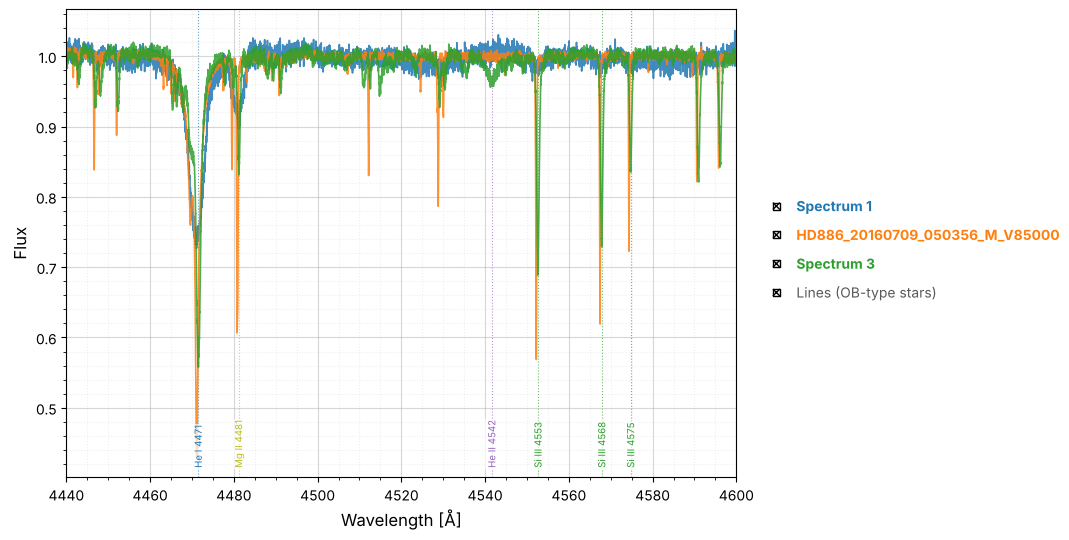


	Figure: ['comparison_demo.pdf', 'comparison_demo.pkl'] in data_and_results/spec/results


In [6]:
to_plot = []  # (spectrum, description) pairs, in plotting order
if flux_norm is not None:
    to_plot.append(((wave_norm, flux_norm), "Normalized HERMES spectrum (example 3)"))
to_plot.append((iacob_fits_file, "IACOB FITS spectrum"))
to_plot.append(((wave_clean, flux_clean), "Cleaned IACOB ASCII spectrum (example 2)"))

description_width = max(len(description) for _, description in to_plot)  # Width of the description column

print(f"\nRange {zoom_range[0]:.0f}-{zoom_range[1]:.0f} Å with the OB-star diagnostic lines.")
if INTERACTIVE:
    print("Use the check buttons to show / hide each spectrum and the lines; close the window to finish.")
print("\nSpectra plotted (label = name of their check button):")
for i, (spectrum, description) in enumerate(to_plot, start=1):
    label = spectrum.stem if isinstance(spectrum, Path) else f"Spectrum {i}"  # Same labels as 'plotspec': file name without extension, or 'Spectrum N'
    print(f"\t{i}. {description:<{description_width}}  Label: {label}")
print()

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    fig_compare = plotspec([spectrum for spectrum, _ in to_plot], wave_lim=zoom_range, show_lines=True, show=True)  # Inline figure, or a Qt window with check buttons if INTERACTIVE
for w in caught:
    print(f"\tWarning: {str(w.message).splitlines()[0]}")

if not INTERACTIVE:  # In interactive mode the window stays open for the check buttons ('savefig_pkl' would close it)
    compare_files = savefig_pkl(fig_compare, compare_fig_file)
    print(f"\n\tFigure: {[p.name for p in compare_files]} in {work_dir_results}")

## Example 5: Writing spectra (writespec)

writespec: the format is chosen from the extension of the output file (ASCII or FITS, optionally gzip-compressed), and every file written is read back with readspec to check that the data are kept.

In [7]:
to_write = []  # (spectrum, output file, header, reference arrays, description)
if flux_norm is not None:
    hermes_header = None  # No header if 'normspec' did not write its output file (e.g. interactive mode without 'w')
    if norm_file.exists():
        # Header lines of the 'normspec' output file (example 3), without the '# ' prefix and without the column names line
        # ('wave' / 'flux' are the names of the FITS table columns; FITS headers do not accept its tab)
        header_lines = []
        with open(norm_file, encoding="utf-8") as f:
            for line in f:
                if not line.startswith("#"):
                    break  # First data line
                header_lines.append(line[2:].rstrip("\n"))
        hermes_header = "\n".join(header_lines[:-1])  # Stored as FITS COMMENT cards (ASCII only)
    to_write.append(((wave_norm, flux_norm), norm_fits_file, hermes_header, (wave_norm, flux_norm), "Normalized HERMES -> FITS (.gz)"))
to_write.append((iacob_fits_file, iacob_converted_file, None, spectra["IACOB (FITS)"], "IACOB FITS image -> ASCII"))

description_width = max(len(description) for *_, description in to_write)  # Width of the description column

print(f"\n\t{'Spectrum':<{description_width}}  {'Output file':<32} {'Points':>8}  Round trip")
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for spectrum, output_file, header, (wave_ref, flux_ref), description in to_write:
        written_file   = writespec(spectrum, output_file, overwrite=True, header=header)  # 'overwrite': the notebook can be run again
        wave_r, flux_r = readspec(written_file)
        same_data      = np.allclose(wave_r, wave_ref, rtol=1e-11, atol=0.) and np.allclose(flux_r, flux_ref, rtol=1e-9, atol=0., equal_nan=True)  # ASCII: '%.12g' / '%.10g'; FITS: float64
        print(f"\t{description:<{description_width}}  {written_file.name:<32} {wave_r.size:8d}  {'data kept' if same_data else 'DIFFERENT'}")

if norm_fits_file.exists() and hermes_header is not None:
    comment_cards = list(fits.getheader(norm_fits_file, "SPECTRUM")['COMMENT'])  # Lines longer than 72 characters are split into several cards
    print(f"\nCOMMENT cards of the 'SPECTRUM' extension of {norm_fits_file.name}:")
    for card in comment_cards:
        print(f"\t{card}")
    same_header = ''.join(comment_cards) == ''.join(hermes_header.splitlines())  # Compared without line breaks, since long lines are split
    print(f"\tSame text as the header of {norm_file.name}: {same_header}")

print(f"\nFirst lines of {iacob_converted_file.name}:")
with open(iacob_converted_file, encoding="utf-8") as f:
    for _ in range(3):
        print(f"\t{f.readline().rstrip()}")

print("\nWarnings in writing the spectra (if any):")
for w in caught:
    print(f"\tWarning: {str(w.message).splitlines()[0]}")


	Spectrum                         Output file                        Points  Round trip
	Normalized HERMES -> FITS (.gz)  HERMES_norm_4000-5000.fits.gz       42909  data kept


	IACOB FITS image -> ASCII        HD886_converted.txt                335533  data kept

COMMENT cards of the 'SPECTRUM' extension of HERMES_norm_4000-5000.fits.gz:
	normspec: output_type=ratio, replace=False
	continuum: function=spline3, order=13, sample=*, naverage=-10, low_rejec
	t=2.0, high_reject=3.0, niterate=10, grow=1.0
	Same text as the header of HERMES_norm_4000-5000.txt: True

First lines of HD886_converted.txt:
	# wave	flux
	3763.765625	1.017419765
	3763.78125	1.010000749

Warnings in writing the spectra (if any):


Particular cases of writespec, with a *mock* 5-point spectrum: descending wavelengths are reversed and non-finite fluxes are kept (with a warning); existing files are only replaced with overwrite=True; unsupported extensions and repeated wavelengths are rejected.

In [8]:
mock_wave = np.array([4475., 4474., 4473., 4472., 4471.])  # Mock spectrum: descending wavelengths [Å]
mock_flux = np.array([1.00, 0.97, np.nan, 0.82, 0.91])  # Mock normalized fluxes, one of them non-finite

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    writespec((mock_wave, mock_flux), mock_file, overwrite=True)

print(f"\nDescending wavelengths and a NaN flux, written to {mock_file.name}:")
with open(mock_file, encoding="utf-8") as f:
    for line in f:
        print(f"\t{line.rstrip()}")
for w in caught:
    print(f"\tWarning: {str(w.message).splitlines()[0]}")

cases = [
         ("Existing file, overwrite=False", (mock_wave, mock_flux), mock_file),
         ("Unsupported extension (.csv)", (mock_wave, mock_flux), work_dir_results / "mock_spectrum.csv"),
         ("Repeated wavelengths", ([4471., 4471., 4472.], [0.90, 0.91, 0.95]), work_dir_results / "mock_repeated.txt"),
        ]

print("\nRejected cases:")
for description, spectrum, output_file in cases:
    try:
        writespec(spectrum, output_file)
        print(f"\t{description:<32} written")
    except (FileExistsError, ValueError) as e:
        print(f"\t{description:<32} {type(e).__name__}: {e}")


Descending wavelengths and a NaN flux, written to mock_spectrum.txt:
	# wave	flux
	4471	0.91
	4472	0.82
	4473	nan
	4474	0.97
	4475	1

Rejected cases:
	Existing file, overwrite=False   FileExistsError: Output file already exists (use 'overwrite=True' to replace it): 'data_and_results/spec/results/mock_spectrum.txt'.
	Unsupported extension (.csv)     ValueError: Output file 'output_file' must have an ASCII ('.txt', '.dat', '.asc', '.ascii') or FITS ('.fits', '.fit', '.fts') extension (optionally followed by .gz). Got 'mock_spectrum.csv'.
	Repeated wavelengths             ValueError: Wavelength array of the spectrum 'spec' must be strictly monotonic. Got 1 repeated or unsorted wavelength(s).
